<a href="https://colab.research.google.com/github/Tabassum-0/Explainable-GNN-Cyberattack-Detection/blob/main/Explainable_GNN_Cyberattack_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Necessary Library

In [ ]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Graph construction
from sklearn.neighbors import NearestNeighbors

# PyTorch and PyTorch Geometric
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, SAGEConv

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Other utilities
import warnings
warnings.filterwarnings("ignore")

print("All imports completed successfully!")
print("PyTorch version:", torch.__version__)
print("PyG version:", torch_geometric.__version__)
print("GPU available:", torch.cuda.is_available())

All imports completed successfully!
PyTorch version: 2.14.1+cpu
PyG version: 2.8.1
GPU available: False


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


##Load Dataset

In [ ]:

# GitHub dataset URLs

train_url = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_training-set.csv"

test_url = "https://raw.githubusercontent.com/Nir-J/ML-Projects/master/UNSW-Network_Packet_Classification/UNSW_NB15_testing-set.csv"

# Load datasets

train = pd.read_csv(train_url)
test = pd.read_csv(test_url)

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

print("Total records:", len(train) + len(test))

Training dataset shape: (175341, 45)
Testing dataset shape: (82332, 45)
Total records: 257673


##Inspect Dataset

In [ ]:

print("TRAINING DATASET")
display(train.head())

print("\nTESTING DATASET")
display(test.head())



TRAINING DATASET


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



TESTING DATASET


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [ ]:
print("\nColumn names:")
print(train.columns.tolist())


Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [ ]:
print("\nTraining information:")
train.info()


Training information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state              175341 non-null  object 
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 no

In [ ]:
print("\nTesting information:")
test.info()


Testing information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 45 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 82332 non-null  int64  
 1   dur                82332 non-null  float64
 2   proto              82332 non-null  object 
 3   service            82332 non-null  object 
 4   state              82332 non-null  object 
 5   spkts              82332 non-null  int64  
 6   dpkts              82332 non-null  int64  
 7   sbytes             82332 non-null  int64  
 8   dbytes             82332 non-null  int64  
 9   rate               82332 non-null  float64
 10  sttl               82332 non-null  int64  
 11  dttl               82332 non-null  int64  
 12  sload              82332 non-null  float64
 13  dload              82332 non-null  float64
 14  sloss              82332 non-null  int64  
 15  dloss              82332 non-null  int64  
 16  

##Target distribution

Training label distribution:
label
1    119341
0     56000
Name: count, dtype: int64

Testing label distribution:
label
1    45332
0    37000
Name: count, dtype: int64


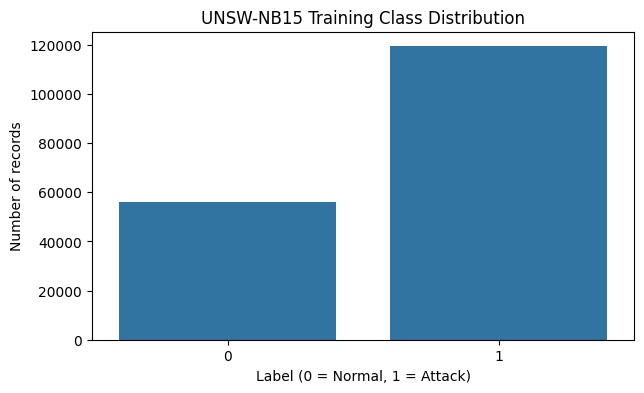

In [ ]:

print("Training label distribution:")
print(train["label"].value_counts())

print("\nTesting label distribution:")
print(test["label"].value_counts())

plt.figure(figsize=(7, 4))

sns.countplot(data=train, x="label")

plt.title("UNSW-NB15 Training Class Distribution")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of records")

plt.show()


##Attack catagories

Attack category distribution:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


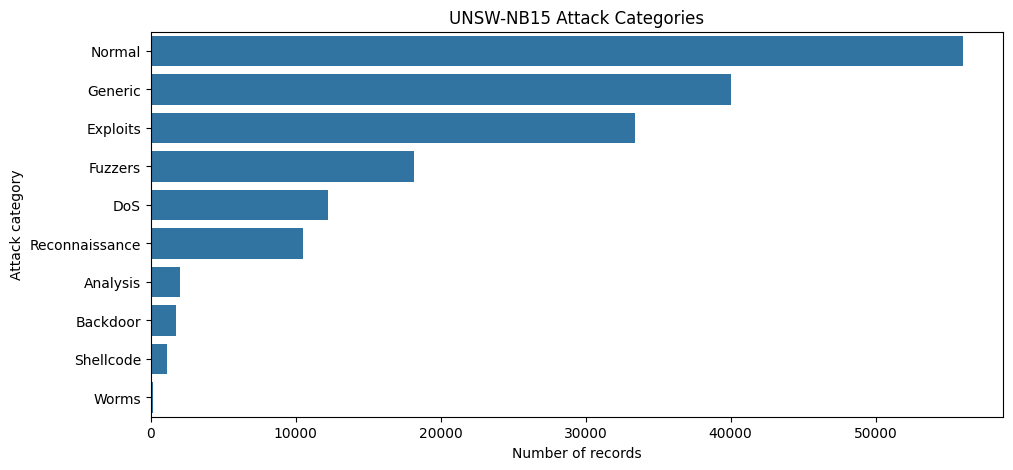

In [ ]:

print("Attack category distribution:")

print(train["attack_cat"].value_counts())

plt.figure(figsize=(11, 5))

sns.countplot(
    data=train,
    y="attack_cat",
    order=train["attack_cat"].value_counts().index
)

plt.title("UNSW-NB15 Attack Categories")
plt.xlabel("Number of records")
plt.ylabel("Attack category")

plt.show()


##Missing value and duplicates

In [ ]:
# Check missing values

print("Missing values in training data:")
print(train.isnull().sum().sum())

print("\nMissing values in testing data:")
print(test.isnull().sum().sum())

# Check duplicate records

print("\nDuplicate records in training:", train.duplicated().sum())
print("Duplicate records in testing:", test.duplicated().sum())

# Check data types

print("\nTraining data types:")
print(train.dtypes.value_counts())


Missing values in training data:
0

Missing values in testing data:
0

Duplicate records in training: 0
Duplicate records in testing: 0

Training data types:
int64      30
float64    11
object      4
Name: count, dtype: int64


##Dataset columns

In [ ]:
print("All columns:")

for i, col in enumerate(train.columns):
    print(i + 1, col)

All columns:
1 id
2 dur
3 proto
4 service
5 state
6 spkts
7 dpkts
8 sbytes
9 dbytes
10 rate
11 sttl
12 dttl
13 sload
14 dload
15 sloss
16 dloss
17 sinpkt
18 dinpkt
19 sjit
20 djit
21 swin
22 stcpb
23 dtcpb
24 dwin
25 tcprtt
26 synack
27 ackdat
28 smean
29 dmean
30 trans_depth
31 response_body_len
32 ct_srv_src
33 ct_state_ttl
34 ct_dst_ltm
35 ct_src_dport_ltm
36 ct_dst_sport_ltm
37 ct_dst_src_ltm
38 is_ftp_login
39 ct_ftp_cmd
40 ct_flw_http_mthd
41 ct_src_ltm
42 ct_srv_dst
43 is_sm_ips_ports
44 attack_cat
45 label


##Numerical and calagorical features

In [ ]:

# Separate numerical and categorical columns

numeric_features = train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label']

Categorical features:
['proto', 'service', 'state', 'attack_cat']


##Separate input features and target labels

In [ ]:

# Separate labels

y_train = train["label"].astype(int).values
y_test = test["label"].astype(int).values

# Remove irrelevant and target columns

drop_columns = ["id", "label", "attack_cat"]

X_train = train.drop(
    columns=drop_columns,
    errors="ignore"
)

X_test = test.drop(
    columns=drop_columns,
    errors="ignore"
)

# Ensure matching feature columns

X_test = X_test.reindex(
    columns=X_train.columns
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (175341, 42)
X_test shape: (82332, 42)
y_train shape: (175341,)
y_test shape: (82332,)


##Preprocessing

###Build preprocessing pipeline

In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify feature types after removing target columns

numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# Fit on training data only

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data

X_test_processed = preprocessor.transform(X_test)

# Convert to float32

X_train_processed = np.asarray(
    X_train_processed,
    dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed,
    dtype=np.float32
)

print("Preprocessing completed!")

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Preprocessing completed!
Processed training shape: (175341, 194)
Processed testing shape: (82332, 194)


###Varify preprocessing

In [ ]:

print("\nTraining label distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting label distribution:")
print(np.unique(y_test, return_counts=True))

print("\nMissing values after preprocessing:")
print(np.isnan(X_train_processed).sum())
print(np.isnan(X_test_processed).sum())



Training label distribution:
(array([0, 1]), array([ 56000, 119341]))

Testing label distribution:
(array([0, 1]), array([37000, 45332]))

Missing values after preprocessing:
0
0


##Sample

In [ ]:

from sklearn.model_selection import train_test_split
import numpy as np

# Select a stratified training sample
train_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=10000,
    stratify=y_train,
    random_state=42
)

# Select a stratified testing sample
test_indices, _ = train_test_split(
    np.arange(len(y_test)),
    train_size=3000,
    stratify=y_test,
    random_state=42
)

X_train_sample = X_train_processed[train_indices]
y_train_sample = y_train[train_indices]

X_test_sample = X_test_processed[test_indices]
y_test_sample = y_test[test_indices]

print("Training sample:", X_train_sample.shape)
print("Testing sample:", X_test_sample.shape)

print("Training labels:", np.unique(y_train_sample, return_counts=True))
print("Testing labels:", np.unique(y_test_sample, return_counts=True))

Training sample: (10000, 194)
Testing sample: (3000, 194)
Training labels: (array([0, 1]), array([3194, 6806]))
Testing labels: (array([0, 1]), array([1348, 1652]))


###KNN Graph

In [ ]:

from sklearn.neighbors import NearestNeighbors
from torch_geometric.data import Data
import scipy.sparse as sp
import torch

def create_knn_graph(X, y, k=10):
    # Find the k nearest neighbours
    knn = NearestNeighbors(
        n_neighbors=k,
        metric="euclidean",
        n_jobs=-1
    )

    knn.fit(X)

    # Create sparse adjacency matrix
    adjacency = knn.kneighbors_graph(
        mode="connectivity"
    )

    # Make the graph undirected
    adjacency = adjacency.maximum(adjacency.T)

    # Convert adjacency matrix into edge_index
    adjacency = adjacency.tocoo()

    edge_index = torch.tensor(
        np.vstack((adjacency.row, adjacency.col)),
        dtype=torch.long
    )

    # Convert features and labels to PyTorch tensors
    x_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)

    # Create PyTorch Geometric graph
    graph = Data(
        x=x_tensor,
        edge_index=edge_index,
        y=y_tensor
    )

    return graph


# Build separate training and testing graphs
train_graph = create_knn_graph(
    X_train_sample,
    y_train_sample,
    k=10
)

test_graph = create_knn_graph(
    X_test_sample,
    y_test_sample,
    k=10
)

print("Training graph:")
print(train_graph)

print("\nTesting graph:")
print(test_graph)

Training graph:
Data(x=[10000, 194], edge_index=[2, 135444], y=[10000])

Testing graph:
Data(x=[3000, 194], edge_index=[2, 41370], y=[3000])


###Check the graph

In [ ]:

print("Training nodes:", train_graph.num_nodes)
print("Training edges:", train_graph.num_edges)

print("Testing nodes:", test_graph.num_nodes)
print("Testing edges:", test_graph.num_edges)

print("Training feature dimensions:", train_graph.num_node_features)
print("Testing feature dimensions:", test_graph.num_node_features)

print("Training graph has isolated nodes:",
      (train_graph.edge_index[0].bincount(
          minlength=train_graph.num_nodes
      ) == 0).sum().item())

Training nodes: 10000
Training edges: 135444
Testing nodes: 3000
Testing edges: 41370
Training feature dimensions: 194
Testing feature dimensions: 194
Training graph has isolated nodes: 0


##GCN model build and train

###Training nodes split

In [ ]:

from sklearn.model_selection import train_test_split
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.nn import GCNConv
import copy
import numpy as np

# Select training and validation node indices
all_indices = np.arange(train_graph.num_nodes)

train_idx, val_idx = train_test_split(
    all_indices,
    test_size=0.20,
    stratify=y_train_sample,
    random_state=42
)

# Create masks
train_mask = torch.zeros(train_graph.num_nodes, dtype=torch.bool)
val_mask = torch.zeros(train_graph.num_nodes, dtype=torch.bool)

train_mask[train_idx] = True
val_mask[val_idx] = True

print("Training nodes:", train_mask.sum().item())
print("Validation nodes:", val_mask.sum().item())

Training nodes: 8000
Validation nodes: 2000


###Define GCN architecture

In [ ]:

class GCN(nn.Module):
    def __init__(self, input_features, hidden_channels, num_classes):
        super(GCN, self).__init__()

        self.conv1 = GCNConv(input_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, num_classes)

        self.dropout = 0.5

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)

        return x


# Initialize model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = GCN(
    input_features=194,
    hidden_channels=64,
    num_classes=2
).to(device)

print("Using device:", device)
print(model)


Using device: cpu
GCN(
  (conv1): GCNConv(194, 64)
  (conv2): GCNConv(64, 2)
)


###Prepare graph & optimizer

In [ ]:

# Move graph and masks to device
train_graph = train_graph.to(device)

train_mask = train_mask.to(device)
val_mask = val_mask.to(device)

# Calculate class weights from training nodes only
class_counts = torch.bincount(
    train_graph.y[train_mask],
    minlength=2
).float()

class_weights = class_counts.sum() / (2 * class_counts)

class_weights = class_weights.to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

Class counts: tensor([2555., 5445.])
Class weights: tensor([1.5656, 0.7346])


###Train the GCN

In [ ]:

best_val_loss = float("inf")
best_model_state = None
patience = 10
patience_counter = 0

for epoch in range(1, 51):

    # Training
    model.train()
    optimizer.zero_grad()

    outputs = model(
        train_graph.x,
        train_graph.edge_index
    )

    loss = criterion(
        outputs[train_mask],
        train_graph.y[train_mask]
    )

    loss.backward()
    optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_outputs = model(
            train_graph.x,
            train_graph.edge_index
        )

        val_loss = criterion(
            val_outputs[val_mask],
            train_graph.y[val_mask]
        )

        val_predictions = val_outputs[val_mask].argmax(dim=1)

        val_accuracy = (
            val_predictions == train_graph.y[val_mask]
        ).float().mean().item()

    # Save best model
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

# Restore the best model
model.load_state_dict(best_model_state)

print("\nTraining completed!")

Epoch 01 | Train Loss: 0.7724 | Val Loss: 0.4592 | Val Accuracy: 0.7690
Epoch 05 | Train Loss: 0.3335 | Val Loss: 0.3012 | Val Accuracy: 0.8795
Epoch 10 | Train Loss: 0.2620 | Val Loss: 0.2443 | Val Accuracy: 0.9040
Epoch 15 | Train Loss: 0.2159 | Val Loss: 0.2193 | Val Accuracy: 0.9200
Epoch 20 | Train Loss: 0.2020 | Val Loss: 0.2062 | Val Accuracy: 0.9205
Epoch 25 | Train Loss: 0.1904 | Val Loss: 0.1963 | Val Accuracy: 0.9140
Epoch 30 | Train Loss: 0.1824 | Val Loss: 0.1876 | Val Accuracy: 0.9210
Epoch 35 | Train Loss: 0.1807 | Val Loss: 0.1790 | Val Accuracy: 0.9225
Epoch 40 | Train Loss: 0.1720 | Val Loss: 0.1741 | Val Accuracy: 0.9225
Epoch 45 | Train Loss: 0.1677 | Val Loss: 0.1692 | Val Accuracy: 0.9275
Epoch 50 | Train Loss: 0.1655 | Val Loss: 0.1686 | Val Accuracy: 0.9220

Training completed!


###Evaluate through testing graph

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

test_graph = test_graph.to(device)

model.eval()

with torch.no_grad():
    test_outputs = model(
        test_graph.x,
        test_graph.edge_index
    )

    test_predictions = test_outputs.argmax(dim=1)

# Convert tensors to NumPy arrays
y_true = test_graph.y.cpu().numpy()
y_pred = test_predictions.cpu().numpy()

# Calculate metrics
print("Test Accuracy:",
      accuracy_score(y_true, y_pred))

print("Test Precision:",
      precision_score(y_true, y_pred, zero_division=0))

print("Test Recall:",
      recall_score(y_true, y_pred, zero_division=0))

print("Test F1 Score:",
      f1_score(y_true, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Test Accuracy: 0.843
Test Precision: 0.8045384218669417
Test Recall: 0.9443099273607748
Test F1 Score: 0.8688387635756056

Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.72      0.80      1348
      Attack       0.80      0.94      0.87      1652

    accuracy                           0.84      3000
   macro avg       0.86      0.83      0.84      3000
weighted avg       0.85      0.84      0.84      3000


Confusion Matrix:
[[ 969  379]
 [  92 1560]]


##MLP Baseline

###Define MLP

In [ ]:

class MLP(nn.Module):
    def __init__(self, input_features, hidden_channels, num_classes):
        super(MLP, self).__init__()

        self.fc1 = nn.Linear(input_features, hidden_channels)
        self.fc2 = nn.Linear(hidden_channels, hidden_channels)
        self.fc3 = nn.Linear(hidden_channels, num_classes)

        self.dropout = 0.5

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = F.relu(self.fc2(x))
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.fc3(x)

        return x


mlp_model = MLP(
    input_features=194,
    hidden_channels=64,
    num_classes=2
).to(device)

mlp_optimizer = torch.optim.Adam(
    mlp_model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print(mlp_model)

MLP(
  (fc1): Linear(in_features=194, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=2, bias=True)
)


###Train MLP

In [ ]:

best_mlp_val_loss = float("inf")
best_mlp_state = None

patience = 10
patience_counter = 0

for epoch in range(1, 51):

    mlp_model.train()
    mlp_optimizer.zero_grad()

    outputs = mlp_model(train_graph.x)

    loss = criterion(
        outputs[train_mask],
        train_graph.y[train_mask]
    )

    loss.backward()
    mlp_optimizer.step()

    # Validation
    mlp_model.eval()

    with torch.no_grad():
        val_outputs = mlp_model(train_graph.x)

        val_loss = criterion(
            val_outputs[val_mask],
            train_graph.y[val_mask]
        )

        val_predictions = val_outputs[val_mask].argmax(dim=1)

        val_accuracy = (
            val_predictions == train_graph.y[val_mask]
        ).float().mean().item()

    if val_loss.item() < best_mlp_val_loss:
        best_mlp_val_loss = val_loss.item()
        best_mlp_state = copy.deepcopy(mlp_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

mlp_model.load_state_dict(best_mlp_state)

print("MLP training completed!")

Epoch 01 | Train Loss: 0.6950 | Val Loss: 0.6329 | Val Accuracy: 0.8040
Epoch 05 | Train Loss: 0.3972 | Val Loss: 0.3235 | Val Accuracy: 0.8665
Epoch 10 | Train Loss: 0.2781 | Val Loss: 0.2366 | Val Accuracy: 0.9220
Epoch 15 | Train Loss: 0.2294 | Val Loss: 0.2131 | Val Accuracy: 0.9300
Epoch 20 | Train Loss: 0.2075 | Val Loss: 0.1980 | Val Accuracy: 0.9250
Epoch 25 | Train Loss: 0.1939 | Val Loss: 0.1837 | Val Accuracy: 0.9250
Epoch 30 | Train Loss: 0.1776 | Val Loss: 0.1724 | Val Accuracy: 0.9230
Epoch 35 | Train Loss: 0.1689 | Val Loss: 0.1617 | Val Accuracy: 0.9240
Epoch 40 | Train Loss: 0.1631 | Val Loss: 0.1573 | Val Accuracy: 0.9230
Epoch 45 | Train Loss: 0.1533 | Val Loss: 0.1557 | Val Accuracy: 0.9205
Epoch 50 | Train Loss: 0.1496 | Val Loss: 0.1557 | Val Accuracy: 0.9220
MLP training completed!


###Evaluate MLP

In [ ]:

mlp_model.eval()

with torch.no_grad():
    mlp_test_outputs = mlp_model(test_graph.x)
    mlp_test_predictions = mlp_test_outputs.argmax(dim=1)

mlp_y_true = test_graph.y.cpu().numpy()
mlp_y_pred = mlp_test_predictions.cpu().numpy()

print("MLP Test Accuracy:",
      accuracy_score(mlp_y_true, mlp_y_pred))

print("MLP Test Precision:",
      precision_score(mlp_y_true, mlp_y_pred, zero_division=0))

print("MLP Test Recall:",
      recall_score(mlp_y_true, mlp_y_pred, zero_division=0))

print("MLP Test F1 Score:",
      f1_score(mlp_y_true, mlp_y_pred, zero_division=0))

print("\nMLP Classification Report:")
print(classification_report(
    mlp_y_true,
    mlp_y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("\nMLP Confusion Matrix:")
print(confusion_matrix(mlp_y_true, mlp_y_pred))


MLP Test Accuracy: 0.8593333333333333
MLP Test Precision: 0.8382838283828383
MLP Test Recall: 0.9225181598062954
MLP Test F1 Score: 0.878386167146974

MLP Classification Report:
              precision    recall  f1-score   support

      Normal       0.89      0.78      0.83      1348
      Attack       0.84      0.92      0.88      1652

    accuracy                           0.86      3000
   macro avg       0.86      0.85      0.86      3000
weighted avg       0.86      0.86      0.86      3000


MLP Confusion Matrix:
[[1054  294]
 [ 128 1524]]


##Implement GraphSAGE

###Define GraphSAGE

In [ ]:

from torch_geometric.nn import SAGEConv

class GraphSAGE(nn.Module):
    def __init__(self, input_features, hidden_channels, num_classes):
        super(GraphSAGE, self).__init__()

        self.conv1 = SAGEConv(input_features, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, num_classes)

        self.dropout = 0.5

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index)

        return x


sage_model = GraphSAGE(
    input_features=194,
    hidden_channels=64,
    num_classes=2
).to(device)

sage_optimizer = torch.optim.Adam(
    sage_model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

print(sage_model)

GraphSAGE(
  (conv1): SAGEConv(194, 64, aggr=mean)
  (conv2): SAGEConv(64, 2, aggr=mean)
)


###Train GraphSAGE

In [ ]:

best_sage_val_loss = float("inf")
best_sage_state = None

patience = 10
patience_counter = 0

for epoch in range(1, 51):

    sage_model.train()
    sage_optimizer.zero_grad()

    outputs = sage_model(
        train_graph.x,
        train_graph.edge_index
    )

    loss = criterion(
        outputs[train_mask],
        train_graph.y[train_mask]
    )

    loss.backward()
    sage_optimizer.step()

    # Validation
    sage_model.eval()

    with torch.no_grad():
        val_outputs = sage_model(
            train_graph.x,
            train_graph.edge_index
        )

        val_loss = criterion(
            val_outputs[val_mask],
            train_graph.y[val_mask]
        )

        val_predictions = val_outputs[val_mask].argmax(dim=1)

        val_accuracy = (
            val_predictions == train_graph.y[val_mask]
        ).float().mean().item()

    if val_loss.item() < best_sage_val_loss:
        best_sage_val_loss = val_loss.item()
        best_sage_state = copy.deepcopy(sage_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if epoch % 5 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {val_accuracy:.4f}"
        )

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

sage_model.load_state_dict(best_sage_state)

print("GraphSAGE training completed!")


Epoch 01 | Train Loss: 0.7080 | Val Loss: 0.4934 | Val Accuracy: 0.7605
Epoch 05 | Train Loss: 0.3429 | Val Loss: 0.2892 | Val Accuracy: 0.8905
Epoch 10 | Train Loss: 0.2358 | Val Loss: 0.2239 | Val Accuracy: 0.9125
Epoch 15 | Train Loss: 0.2037 | Val Loss: 0.1984 | Val Accuracy: 0.9170
Epoch 20 | Train Loss: 0.1835 | Val Loss: 0.1785 | Val Accuracy: 0.9150
Epoch 25 | Train Loss: 0.1708 | Val Loss: 0.1693 | Val Accuracy: 0.9160
Epoch 30 | Train Loss: 0.1648 | Val Loss: 0.1642 | Val Accuracy: 0.9220
Epoch 35 | Train Loss: 0.1588 | Val Loss: 0.1641 | Val Accuracy: 0.9190
Epoch 40 | Train Loss: 0.1553 | Val Loss: 0.1626 | Val Accuracy: 0.9200
Epoch 45 | Train Loss: 0.1518 | Val Loss: 0.1627 | Val Accuracy: 0.9190
Epoch 50 | Train Loss: 0.1519 | Val Loss: 0.1619 | Val Accuracy: 0.9195
GraphSAGE training completed!


###Evaluate GraphSAGE

In [ ]:

sage_model.eval()

with torch.no_grad():
    sage_test_outputs = sage_model(
        test_graph.x,
        test_graph.edge_index
    )

    sage_test_predictions = sage_test_outputs.argmax(dim=1)

sage_y_true = test_graph.y.cpu().numpy()
sage_y_pred = sage_test_predictions.cpu().numpy()

print("GraphSAGE Test Accuracy:",
      accuracy_score(sage_y_true, sage_y_pred))

print("GraphSAGE Test Precision:",
      precision_score(sage_y_true, sage_y_pred, zero_division=0))

print("GraphSAGE Test Recall:",
      recall_score(sage_y_true, sage_y_pred, zero_division=0))

print("GraphSAGE Test F1 Score:",
      f1_score(sage_y_true, sage_y_pred, zero_division=0))

print("\nGraphSAGE Classification Report:")
print(classification_report(
    sage_y_true,
    sage_y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("\nGraphSAGE Confusion Matrix:")
print(confusion_matrix(sage_y_true, sage_y_pred))

GraphSAGE Test Accuracy: 0.8563333333333333
GraphSAGE Test Precision: 0.826296098343132
GraphSAGE Test Recall: 0.9358353510895884
GraphSAGE Test F1 Score: 0.8776610843031507

GraphSAGE Classification Report:
              precision    recall  f1-score   support

      Normal       0.91      0.76      0.83      1348
      Attack       0.83      0.94      0.88      1652

    accuracy                           0.86      3000
   macro avg       0.87      0.85      0.85      3000
weighted avg       0.86      0.86      0.85      3000


GraphSAGE Confusion Matrix:
[[1023  325]
 [ 106 1546]]


##Explainability with GNNExplainer

###Import GNNExplainer

In [ ]:

from torch_geometric.explain import Explainer, GNNExplainer

print("GNNExplainer is ready!")


GNNExplainer is ready!


###Select an attack prediction to explain

In [ ]:
# Find attacks correctly classified by GCN
correct_gcn_attacks = torch.where(
    (test_graph.y == 1) &
    (test_predictions == 1)
)[0]

print("Correctly classified GCN attacks:",
      len(correct_gcn_attacks))

# Select one attack node
node_idx = int(correct_gcn_attacks[0].item())

print("Selected node:", node_idx)
print("Actual class:", test_graph.y[node_idx].item())
print("GCN prediction:", test_predictions[node_idx].item())


Correctly classified GCN attacks: 1560
Selected node: 1
Actual class: 1
GCN prediction: 1


###Configure GNNExplainer

In [ ]:

# Configure GNNExplainer for node classification
explainer = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=200),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

print("GNNExplainer configured successfully!")


GNNExplainer configured successfully!


###Generate an explanation

In [ ]:

# GCN must be in evaluation mode
model.eval()

explanation = explainer(
    test_graph.x,
    test_graph.edge_index,
    index=node_idx
)

print("Explanation generated!")

print("Node mask shape:", explanation.node_mask.shape)
print("Edge mask shape:", explanation.edge_mask.shape)


Explanation generated!
Node mask shape: torch.Size([3000, 194])
Edge mask shape: torch.Size([41370])


###Identify the most important features

In [ ]:

# Retrieve feature names
feature_names = preprocessor.get_feature_names_out()

# Get feature importance for the selected node
node_mask = explanation.node_mask

if node_mask.dim() == 2:
    feature_importance = node_mask[node_idx]
else:
    feature_importance = node_mask

feature_importance = feature_importance.detach().cpu().numpy()

# Rank features
top_indices = np.argsort(feature_importance)[::-1][:10]

print("Top 10 important features for this attack prediction:\n")

for rank, idx in enumerate(top_indices, start=1):
    print(
        f"{rank}. {feature_names[idx]}: "
        f"{feature_importance[idx]:.4f}"
    )

Top 10 important features for this attack prediction:

1. num__dtcpb: 0.8399
2. num__ct_dst_sport_ltm: 0.8215
3. num__ct_src_ltm: 0.8182
4. num__smean: 0.8137
5. cat__state_INT: 0.8107
6. num__stcpb: 0.8061
7. num__sttl: 0.8024
8. num__dmean: 0.7999
9. num__swin: 0.7984
10. cat__service_dns: 0.7920


###Identify important graph connections

In [ ]:

edge_mask = explanation.edge_mask.detach().cpu().numpy()
explained_edges = explanation.edge_index.cpu().numpy()

top_edge_indices = np.argsort(edge_mask)[::-1][:10]

print("Top important graph connections:\n")

for rank, edge_idx in enumerate(top_edge_indices, start=1):
    source = explained_edges[0, edge_idx]
    target = explained_edges[1, edge_idx]

    print(
        f"{rank}. Node {source} -> Node {target} | "
        f"Importance: {edge_mask[edge_idx]:.4f}"
    )

Top important graph connections:

1. Node 1146 -> Node 1 | Importance: 0.8499
2. Node 1638 -> Node 1 | Importance: 0.8492
3. Node 1587 -> Node 1 | Importance: 0.8480
4. Node 2118 -> Node 1 | Importance: 0.8472
5. Node 41 -> Node 1 | Importance: 0.8418
6. Node 1397 -> Node 1 | Importance: 0.8413
7. Node 1762 -> Node 1 | Importance: 0.8404
8. Node 2360 -> Node 1 | Importance: 0.8403
9. Node 1129 -> Node 1 | Importance: 0.8367
10. Node 1579 -> Node 1 | Importance: 0.8327


###Visualize feature importance

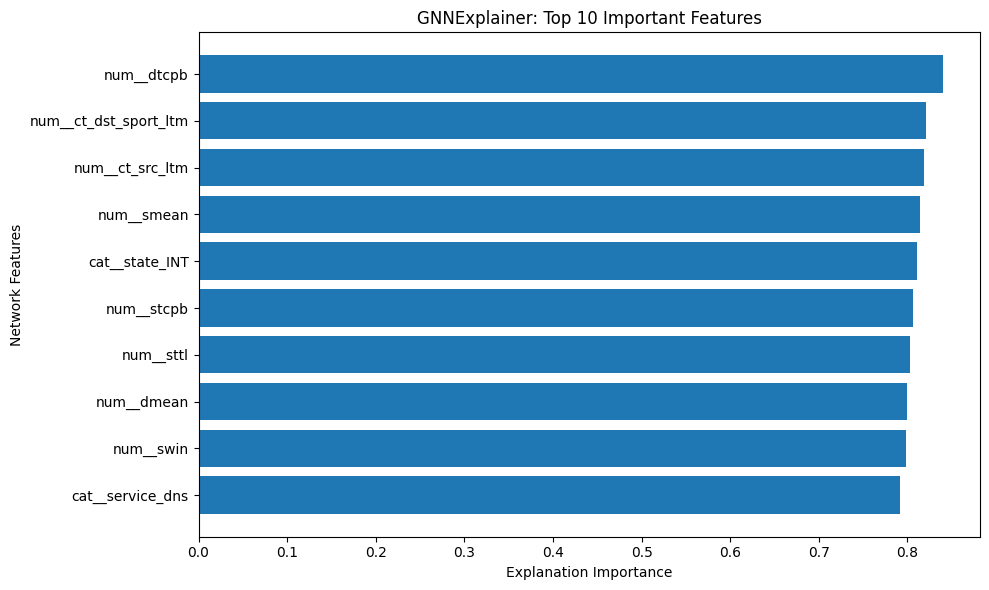

In [ ]:

import matplotlib.pyplot as plt

top_names = feature_names[top_indices][::-1]
top_values = feature_importance[top_indices][::-1]

plt.figure(figsize=(10, 6))

plt.barh(top_names, top_values)

plt.xlabel("Explanation Importance")
plt.ylabel("Network Features")
plt.title("GNNExplainer: Top 10 Important Features")

plt.tight_layout()
plt.show()